In [1]:
# ============================================================
# STEP 0: Imports and Global Configuration
# ============================================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# -----------------------------
# Reproducibility
# -----------------------------
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# -----------------------------
# Model & Image Parameters
# -----------------------------
IMG_SIZE = (224, 224)          # MobileNetV2 standard
BATCH_SIZE = 32
THRESHOLD = 0.5                # Fixed decision threshold

print("Environment ready.")


Environment ready.


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
model_files = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith(".keras") or file.endswith(".h5"):
            model_files.append(os.path.join(root, file))

print("Saved model files found:\n")
for f in model_files:
    print(f)


Saved model files found:

/content/drive/MyDrive/resnet50_mendeley_best.h5
/content/drive/MyDrive/MobileNetV2_Finetuned_Best.keras
/content/drive/MyDrive/Fusion_MobileNetV2_ResNet50_Best.keras
/content/drive/MyDrive/models/model_2_1.keras
/content/drive/MyDrive/models/MobileNet_Binary_FIXED.keras
/content/drive/MyDrive/models/MobileNet_Binary_not.keras
/content/drive/MyDrive/models/Copy of MobileNet_Binary_not.keras
/content/drive/MyDrive/Fruit_CNN_Models/phase1_baseline_cnn.keras
/content/drive/MyDrive/Fruit_CNN_Models/phase2_early_stopping.keras
/content/drive/MyDrive/Fruit_CNN_Models/phaseC1_cnn_augmented.keras
/content/drive/MyDrive/Fruit_CNN_Models/phaseC2_cnn_early_stop.keras
/content/drive/MyDrive/Model1_Fruit_vs_NonFruit_FINAL/model1_best.keras
/content/drive/MyDrive/Model1_Fruit_vs_NonFruit_FINAL/model1_final.keras
/content/drive/MyDrive/Model1_Fruit_vs_NonFruit_FINAL/model1_finetuned_best.keras
/content/drive/MyDrive/Model1_Fruit_vs_NonFruit_FINAL/model1_finetuned_final.keras

In [5]:
# ============================================================
# STEP 1: Load Trained MobileNetV2 Model
# ============================================================

MODEL_PATH = "/content/drive/MyDrive/freshness_runtime_models/MobileNet_16_Finetuned.keras"
# 🔁 CHANGE PATH if needed

model = load_model(MODEL_PATH)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,278,480 (8.69 MB)

 Trainable params: 1,701,840 (6.49 MB)

 Non-trainable params: 576,640 (2.20 MB)

In [6]:
# ============================================================
# STEP 2 (UPDATED): Evaluation + Confusion Matrix Visualization
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

def evaluate_model_with_cm(model, generator, dataset_name):
    """
    Evaluates a binary classification model and plots confusion matrix.
    Assumptions:
    - Sigmoid output
    - Fresh = 0, Rotten = 1
    """

    # Reset generator
    generator.reset()

    # Predict probabilities
    y_prob = model.predict(generator, verbose=1).ravel()

    # Apply fixed threshold
    y_pred = (y_prob >= THRESHOLD).astype(int)

    # True labels
    y_true = generator.classes

    # Metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)

    # Print metrics
    print(f"\n📊 Results — {dataset_name}")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=["Fresh", "Rotten"]))

    # -----------------------------
    # Confusion Matrix Plot
    # -----------------------------
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Fresh", "Rotten"]
    )

    fig, ax = plt.subplots(figsize=(5, 4))
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    plt.title(f"Confusion Matrix — {dataset_name}")
    plt.show()

    return {
        "dataset": dataset_name,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "confusion_matrix": cm
    }


In [7]:
!ls "/content/drive/MyDrive"


'50_Startups (1).csv.gsheet'
 50_Startups.csv.gsheet
 aiapple.jpg
 aibanana.webp
 aiorange.png
 applebad.jpg
 apple-gone-bad.jpg
'Augmented Image (1).zip'
 Binary_Freshness_Dataset
' BRANCH_CHANGE_APPLICATION.gdoc'
'BT24CSD066(RAKSHIT LADDA)MINDEASE.pdf'
'BT24CSD066(RAKSHIT LADDA).png'
'BT24ECE063. RAKSHIT LADDA.pdf'
 Classroom
 classwise_model_results.csv
'Colab Notebooks'
'Copy of ELECTRICALAPPROVAL.gdoc'
 cross_dataset_results
'Document from Rakshit Ladda.pdf'
'eee assingment.pdf'
 FIXED_MODELS
 freshness_config.json
 freshness_results
 freshness_results_final
 freshness_results_fixed
 freshness_results_v2
 freshness_results_v3
 freshness_runtime_models
 Fruit_CNN_Models
 Fusion_MobileNetV2_ResNet50_Best.keras
 gradcam_samples
 gradcam_test_image_list.csv
 gradcam_test_results
 IMG-20240708-WA0001.jpg
 IMG-20241010-WA0035.jpg
 IMG-20251004-WA0007.jpg
 impact-of-internet-of-things-on-society-IJERTCONV5IS03020.pdf
'mango_pomo_some org_fresh.jpeg'
 mendeley_16class_dataset
 MobileNetV2

In [9]:
# ============================================================
# DATASET 1: MENDELEY TEST SET
# ============================================================

MENDELEY_TEST_DIR = "/content/drive/MyDrive/mendeley_16class_dataset/test"
# 🔁 CHANGE PATH if needed

test_datagen = ImageDataGenerator(rescale=1./255)

mendeley_test_gen = test_datagen.flow_from_directory(
    MENDELEY_TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

print("Class mapping:", mendeley_test_gen.class_indices)


Found 640 images belonging to 16 classes.
Class mapping: {'FreshApple': 0, 'FreshBanana': 1, 'FreshGrape': 2, 'FreshGuava': 3, 'FreshJujube': 4, 'FreshOrange': 5, 'FreshPomegranate': 6, 'FreshStrawberry': 7, 'RottenApple': 8, 'RottenBanana': 9, 'RottenGrape': 10, 'RottenGuava': 11, 'RottenJujube': 12, 'RottenOrange': 13, 'RottenPomegranate': 14, 'RottenStrawberry': 15}


20/20 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step

📊 Results — Mendeley (In-distribution)
Accuracy : 0.9828
Precision: 1.0000
Recall   : 0.9656
F1-score : 0.9825

Classification Report:
              precision    recall  f1-score   support

       Fresh       0.97      1.00      0.98       320
      Rotten       1.00      0.97      0.98       320

    accuracy                           0.98       640
   macro avg       0.98      0.98      0.98       640
weighted avg       0.98      0.98      0.98       640



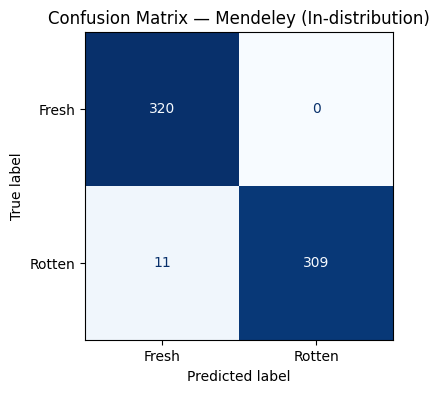

In [11]:
# ============================================================
# Evaluate MobileNetV2 — In-Distribution
# ============================================================

# Assuming the model is a 16-class classifier
# And we want to evaluate it in a binary Fresh (0-7) / Rotten (8-15) context.

mendeley_test_gen.reset()

# Predict probabilities for each of the 16 classes
y_prob_multiclass = model.predict(mendeley_test_gen, verbose=1) # Shape: (samples, 16)

# Determine the predicted class index (0-15) by taking the argmax
y_pred_multiclass_idx = np.argmax(y_prob_multiclass, axis=1) # Shape: (samples,)

# Map the 16 predicted class indices to binary (0 for Fresh, 1 for Rotten)
# Based on the mendeley_test_gen.class_indices: Fresh (0-7), Rotten (8-15)
y_pred_binary = (y_pred_multiclass_idx >= 8).astype(int) # Shape: (samples,)

# True labels (0-15 from generator.classes)
y_true_multiclass_idx = mendeley_test_gen.classes # Shape: (samples,)

# Map the true class indices to binary (0 for Fresh, 1 for Rotten)
y_true_binary = (y_true_multiclass_idx >= 8).astype(int) # Shape: (samples,)

# Now y_true_binary and y_pred_binary should both have shape (samples,) and contain 0s and 1s.
# Imports for metrics and plotting (already available globally, but included for clarity in this cell's context)
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Metrics
acc = accuracy_score(y_true_binary, y_pred_binary)
prec = precision_score(y_true_binary, y_pred_binary)
rec = recall_score(y_true_binary, y_pred_binary)
f1 = f1_score(y_true_binary, y_pred_binary)
cm = confusion_matrix(y_true_binary, y_pred_binary)

dataset_name = "Mendeley (In-distribution)"
print(f"\n📊 Results — {dataset_name}")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true_binary, y_pred_binary, target_names=["Fresh", "Rotten"]))

# Confusion Matrix Plot
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fresh", "Rotten"]
)

fig, ax = plt.subplots(figsize=(5, 4))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title(f"Confusion Matrix — {dataset_name}")
plt.show()

mendeley_results = {
    "dataset": dataset_name,
    "accuracy": acc,
    "precision": prec,
    "recall": rec,
    "f1": f1,
    "confusion_matrix": cm
}

In [14]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [15]:
!kaggle datasets list

ref                                                            title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-------------------------------------------------------------  --------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
nalisha/job-salary-prediction-dataset                          Job Salary Prediction Dataset                          3144815  2026-03-16 19:54:33.843000           3907         90                1  
ssssws/chocolate-sales-dataset-2023-2024                       Chocolate Sales Dataset 2023 - 2024                   24420255  2026-03-07 04:58:02.387000           7340        122                1  
sharmajicoder/student-mental-health-and-burnout                Student Mental Health and Burnout                    137596875  2026-03-18 19:03:34.140000           1318         35                1  
grand

In [16]:
!kaggle datasets download -d sriramr/fruits-fresh-and-rotten-for-classification


Dataset URL: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification
License(s): unknown
100% 3.58G/3.58G [01:30<00:00, 42.7MB/s]



In [17]:
!unzip fruits-fresh-and-rotten-for-classification.zip -d /content/kaggle_fruits


Streaming output truncated to the last 5000 lines.
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.09 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.18 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.24 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.37 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.51 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.02 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.12 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.2

In [18]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_dir = "/content/kaggle_fruits/dataset/test"

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode=None,   # IMPORTANT
    shuffle=False
)


Found 2698 images belonging to 6 classes.


In [19]:
import numpy as np

binary_labels = []

for path in test_generator.filepaths:
    folder = path.split("/")[-2].lower()

    if folder.startswith("fresh"):
        binary_labels.append(0)   # Fresh
    elif folder.startswith("rotten"):
        binary_labels.append(1)   # Rotten
    else:
        raise ValueError(f"Unknown class: {folder}")

y_true = np.array(binary_labels)


In [22]:
# Predict probabilities for each of the 16 classes
y_prob_multiclass = model.predict(test_generator, verbose=1)

# Determine the predicted class index (0-15) by taking the argmax
y_pred_multiclass_idx = np.argmax(y_prob_multiclass, axis=1)

# Map the 16 predicted class indices to binary (0 for Fresh, 1 for Rotten)
# Assuming classes 0-7 are Fresh and 8-15 are Rotten (based on Mendeley dataset structure)
y_pred = (y_pred_multiclass_idx >= 8).astype(int)

85/85 ━━━━━━━━━━━━━━━━━━━━ 21s 247ms/step


In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1-score :", f1_score(y_true, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=["Fresh", "Rotten"]))


Accuracy : 0.6567828020756116
Precision: 0.8355408388520972
Recall   : 0.4934810951760104
F1-score : 0.6204918032786885

Classification Report:

              precision    recall  f1-score   support

       Fresh       0.57      0.87      0.69      1164
      Rotten       0.84      0.49      0.62      1534

    accuracy                           0.66      2698
   macro avg       0.70      0.68      0.65      2698
weighted avg       0.72      0.66      0.65      2698



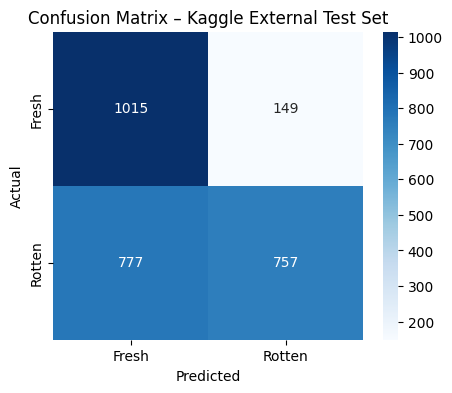

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fresh", "Rotten"],
    yticklabels=["Fresh", "Rotten"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Kaggle External Test Set")
plt.show()


In [ ]:
!kaggle datasets download -d riescoalieffe/fruitmate



Dataset URL: https://www.kaggle.com/datasets/riescoalieffe/fruitmate
License(s): unknown
  0% 0.00/12.6M [00:00<?, ?B/s]
100% 12.6M/12.6M [00:00<00:00, 402MB/s]


In [ ]:
!unzip fruitmate.zip -d /content/fruitmate


Archive:  fruitmate.zip
  inflating: /content/fruitmate/Testing/Overripe/Overripe004.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe006.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe007.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe008.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe011.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe012.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe021.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe022.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe023.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe027.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe028.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe029.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe036.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe038.jpeg  
  inflating: /content/fr

In [ ]:
import os

os.listdir("/content/fruitmate/Testing")


['Unripe', 'Overripe', 'Ripe']

In [ ]:
# ============================================================
# DATASET 3: FRUITMATE
# ============================================================

from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

FRUITMATE_TEST_DIR = "/content/fruitmate/Testing"
# 🔁 CHANGE PATH if needed

test_datagen = ImageDataGenerator(rescale=1./255)

fruitmate_test_gen = test_datagen.flow_from_directory(
    FRUITMATE_TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode=None,   # intentional
    shuffle=False
)

print("Total FruitMate samples:", fruitmate_test_gen.samples)


Found 57 images belonging to 3 classes.
Total FruitMate samples: 57


In [ ]:
# ============================================================
# Construct Binary Labels
# ============================================================

binary_labels = []

for path in fruitmate_test_gen.filepaths:
    folder = path.split("/")[-2].lower()

    if "ripe" in folder and "over" not in folder:
        binary_labels.append(0)   # Fresh
    elif "overripe" in folder or "over_ripe" in folder:
        binary_labels.append(1)   # Rotten
    else:
        raise ValueError(f"Unrecognized class folder: {folder}")

y_true = np.array(binary_labels)


In [ ]:
# ============================================================
# Predict on FruitMate
# ============================================================

y_prob = model.predict(fruitmate_test_gen, verbose=1)
y_pred = (y_prob >= THRESHOLD).astype(int).ravel()


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 910ms/step


📊 FruitMate Results
Accuracy : 0.8947368421052632
Precision: 1.0
Recall   : 0.6842105263157895
F1-score : 0.8125

Classification Report:
              precision    recall  f1-score   support

       Fresh       0.86      1.00      0.93        38
      Rotten       1.00      0.68      0.81        19

    accuracy                           0.89        57
   macro avg       0.93      0.84      0.87        57
weighted avg       0.91      0.89      0.89        57



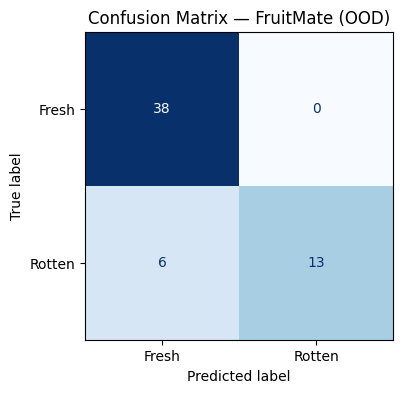

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Metrics
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred)

print("📊 FruitMate Results")
print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=["Fresh", "Rotten"]))

# Confusion Matrix Plot
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fresh", "Rotten"]
)

fig, ax = plt.subplots(figsize=(5, 4))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix — FruitMate (OOD)")
plt.show()


In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [ ]:
# Download Fruits Quality (Fresh vs Rotten)
!kaggle datasets download -d nourabdoun/fruits-quality-fresh-vs-rotten


Dataset URL: https://www.kaggle.com/datasets/nourabdoun/fruits-quality-fresh-vs-rotten
License(s): other
fruits-quality-fresh-vs-rotten.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
# Unzip dataset
!unzip -q fruits-quality-fresh-vs-rotten.zip -d /content/fruit_quality


In [ ]:
!ls /content/fruit_quality
!find /content/fruit_quality -maxdepth 2 -type d


 Dataset   Dataset_v1   Dataset_v2  'Quality Dataset'
/content/fruit_quality
/content/fruit_quality/Quality Dataset
/content/fruit_quality/Quality Dataset/train
/content/fruit_quality/Quality Dataset/test
/content/fruit_quality/Quality Dataset/valid
/content/fruit_quality/Dataset_v2
/content/fruit_quality/Dataset_v2/train
/content/fruit_quality/Dataset_v2/test
/content/fruit_quality/Dataset_v2/valid
/content/fruit_quality/Dataset
/content/fruit_quality/Dataset/train
/content/fruit_quality/Dataset/test
/content/fruit_quality/Dataset/valid
/content/fruit_quality/Dataset_v1
/content/fruit_quality/Dataset_v1/train
/content/fruit_quality/Dataset_v1/test
/content/fruit_quality/Dataset_v1/valid


In [ ]:
!ls "/content/fruit_quality/Quality Dataset/test"


fresh  rotten


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

TEST_DIR = "/content/fruit_quality/Quality Dataset/test"

test_datagen = ImageDataGenerator(rescale=1./255)

fruit_quality_test_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

print("Class mapping:", fruit_quality_test_gen.class_indices)
print("Total samples:", fruit_quality_test_gen.samples)


Found 24 images belonging to 2 classes.
Class mapping: {'fresh': 0, 'rotten': 1}
Total samples: 24


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 969ms/step

📊 Results — Fruit Quality (Kaggle OOD)
Accuracy : 0.7083
Precision: 0.8571
Recall   : 0.5000
F1-score : 0.6316

Classification Report:
              precision    recall  f1-score   support

       Fresh       0.65      0.92      0.76        12
      Rotten       0.86      0.50      0.63        12

    accuracy                           0.71        24
   macro avg       0.75      0.71      0.70        24
weighted avg       0.75      0.71      0.70        24



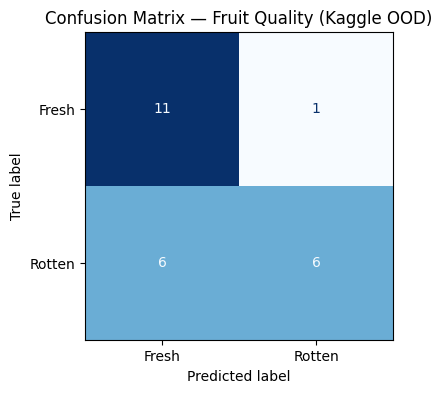

In [ ]:
fruit_quality_results = evaluate_model_with_cm(
    model,
    fruit_quality_test_gen,
    dataset_name="Fruit Quality (Kaggle OOD)"
)


In [ ]:
!unzip "/content/drive/MyDrive/Original Image -2.zip" -d "/content/fruitvision_raw"


Streaming output truncated to the last 5000 lines.
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63714.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63715.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63716.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63717.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63718.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63719.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63720.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63721.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63722.jpg  
  inflating: /content/fruitvision_raw/Fruits Original/Grape/Fresh/msg5170347760-63723.jpg  
  inflating: /content/fruitvi

In [ ]:
import os

os.listdir("/content/fruitvision_raw")


['Fruits Original']

In [ ]:
SOURCE_DIR = "/content/fruitvision_raw/Fruits Original"
TARGET_DIR = "/content/fruitvision_test_clean"


In [ ]:
import os
import shutil

if os.path.exists(TARGET_DIR):
    shutil.rmtree(TARGET_DIR)

os.makedirs(os.path.join(TARGET_DIR, "Fresh"), exist_ok=True)
os.makedirs(os.path.join(TARGET_DIR, "Rotten"), exist_ok=True)


In [ ]:
for folder in os.listdir(SOURCE_DIR):
    folder_path = os.path.join(SOURCE_DIR, folder)
    if not os.path.isdir(folder_path):
        continue

    folder_lower = folder.lower()

    if folder_lower.startswith("fresh"):
        target_class = "Fresh"
    elif folder_lower.startswith("rotten"):
        target_class = "Rotten"
    else:
        # This skips all Formalin-mixed folders
        continue

    for img in os.listdir(folder_path):
        shutil.copy(
            os.path.join(folder_path, img),
            os.path.join(TARGET_DIR, target_class, img)
        )


In [ ]:
import os, shutil

TARGET_DIR = "/content/fruitvision_test_clean"

if os.path.exists(TARGET_DIR):
    shutil.rmtree(TARGET_DIR)

os.makedirs(os.path.join(TARGET_DIR, "Fresh"), exist_ok=True)
os.makedirs(os.path.join(TARGET_DIR, "Rotten"), exist_ok=True)


In [ ]:
SOURCE_DIR = "/content/fruitvision_raw/Fruits Original"

image_extensions = (".jpg", ".jpeg", ".png")

fresh_count = 0
rotten_count = 0

for root, dirs, files in os.walk(SOURCE_DIR):
    folder_name = os.path.basename(root).lower()

    if "formalin" in folder_name:
        continue

    if "fresh" in folder_name:
        target_class = "Fresh"
    elif "rotten" in folder_name:
        target_class = "Rotten"
    else:
        continue

    for file in files:
        if file.lower().endswith(image_extensions):
            src = os.path.join(root, file)
            dst = os.path.join(TARGET_DIR, target_class, file)
            shutil.copy(src, dst)

            if target_class == "Fresh":
                fresh_count += 1
            else:
                rotten_count += 1


In [ ]:
print("Fresh images copied :", fresh_count)
print("Rotten images copied:", rotten_count)


Fresh images copied : 3800
Rotten images copied: 3178


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    "/content/fruitvision_test_clean",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

print("Class indices:", test_generator.class_indices)


Found 6918 images belonging to 2 classes.
Class indices: {'Fresh': 0, 'Rotten': 1}


In [ ]:
y_prob = model.predict(test_generator, verbose=1)
y_pred = (y_prob >= 0.5).astype(int).flatten()
y_true = test_generator.classes


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


217/217 ━━━━━━━━━━━━━━━━━━━━ 369s 2s/step


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_true,
    y_pred,
    target_names=["Fresh", "Rotten"]
))


              precision    recall  f1-score   support

       Fresh       0.79      0.85      0.82      3740
      Rotten       0.81      0.74      0.77      3178

    accuracy                           0.80      6918
   macro avg       0.80      0.79      0.80      6918
weighted avg       0.80      0.80      0.80      6918



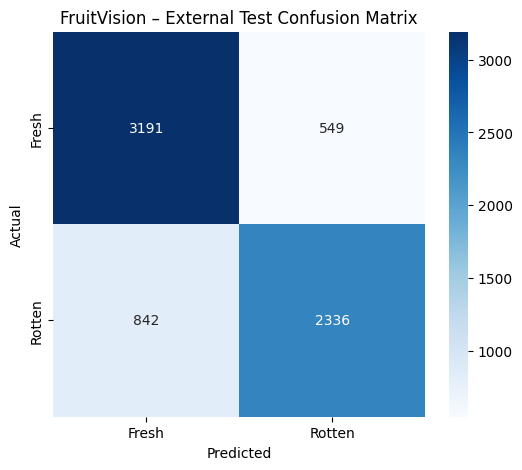

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fresh", "Rotten"],
            yticklabels=["Fresh", "Rotten"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("FruitVision – External Test Confusion Matrix")
plt.show()


In [ ]:
!kaggle datasets download -d amitsubhashagrahari/fresh-or-rotten-fruit


Dataset URL: https://www.kaggle.com/datasets/amitsubhashagrahari/fresh-or-rotten-fruit
License(s): apache-2.0
fresh-or-rotten-fruit.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!unzip fresh-or-rotten-fruit.zip -d /content/fresh_rotten_external


Archive:  fresh-or-rotten-fruit.zip
  inflating: /content/fresh_rotten_external/Dataset_1/1.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/10.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/100.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/101.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/102.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/103.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/104.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/105.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/106.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/107.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/108.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/109.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/11.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/110.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/111.

In [ ]:
os.listdir("/content/fresh_rotten_external")


['Dataset_1']

In [ ]:
os.listdir("/content/fresh_rotten_external/Dataset_1")


['190.jpeg',
 '181.jpeg',
 '159.jpeg',
 '88.jpeg',
 '21.jpeg',
 '118.jpeg',
 '151.jpeg',
 '92.jpeg',
 '35.jpeg',
 '6.jpg',
 '19.jpeg',
 '125.jpeg',
 '202.jpeg',
 '123.jpeg',
 '169.jpeg',
 '185.jpeg',
 '132.jpeg',
 '4.jpeg',
 '184.jpeg',
 '131.jpeg',
 '139.jpeg',
 '121.jpeg',
 '141.jpeg',
 '208.jpeg',
 '152.jpeg',
 '14.jpeg',
 '93.jpeg',
 '119.jpeg',
 '51.jpeg',
 '30.jpeg',
 '188.jpeg',
 '72.jpeg',
 '149.jpeg',
 '48.jpeg',
 '218.jpeg',
 '223.jpeg',
 '2.jpeg',
 '13.jpeg',
 '45.jpeg',
 '80.jpeg',
 '148.jpeg',
 '31.jpeg',
 '158.jpeg',
 '47.jpeg',
 '43.jpeg',
 '126.jpeg',
 '34.jpeg',
 '140.jpeg',
 '44.jpeg',
 '23.jpeg',
 '101.jpeg',
 '64.jpeg',
 '137.jpeg',
 '22.jpeg',
 '183.jpeg',
 '225.jpeg',
 '170.jpeg',
 '130.jpeg',
 '67.jpeg',
 '40.jpeg',
 '144.jpeg',
 '85.jpeg',
 '29.jpeg',
 '79.jpeg',
 '142.jpeg',
 '111.jpeg',
 '167.jpeg',
 '86.jpeg',
 '42.jpeg',
 '194.jpeg',
 '28.jpeg',
 '129.jpeg',
 '94.jpeg',
 '157.jpeg',
 '200.jpeg',
 '6.jpeg',
 '204.jpeg',
 '145.jpeg',
 '69.jpeg',
 '179.jpeg',
 

In [ ]:
os.listdir("/content/fresh_rotten_external")


['Dataset_1']

In [ ]:
os.listdir("/content/fresh_rotten_external/Dataset_1")


['190.jpeg',
 '181.jpeg',
 '159.jpeg',
 '88.jpeg',
 '21.jpeg',
 '118.jpeg',
 '151.jpeg',
 '92.jpeg',
 '35.jpeg',
 '6.jpg',
 '19.jpeg',
 '125.jpeg',
 '202.jpeg',
 '123.jpeg',
 '169.jpeg',
 '185.jpeg',
 '132.jpeg',
 '4.jpeg',
 '184.jpeg',
 '131.jpeg',
 '139.jpeg',
 '121.jpeg',
 '141.jpeg',
 '208.jpeg',
 '152.jpeg',
 '14.jpeg',
 '93.jpeg',
 '119.jpeg',
 '51.jpeg',
 '30.jpeg',
 '188.jpeg',
 '72.jpeg',
 '149.jpeg',
 '48.jpeg',
 '218.jpeg',
 '223.jpeg',
 '2.jpeg',
 '13.jpeg',
 '45.jpeg',
 '80.jpeg',
 '148.jpeg',
 '31.jpeg',
 '158.jpeg',
 '47.jpeg',
 '43.jpeg',
 '126.jpeg',
 '34.jpeg',
 '140.jpeg',
 '44.jpeg',
 '23.jpeg',
 '101.jpeg',
 '64.jpeg',
 '137.jpeg',
 '22.jpeg',
 '183.jpeg',
 '225.jpeg',
 '170.jpeg',
 '130.jpeg',
 '67.jpeg',
 '40.jpeg',
 '144.jpeg',
 '85.jpeg',
 '29.jpeg',
 '79.jpeg',
 '142.jpeg',
 '111.jpeg',
 '167.jpeg',
 '86.jpeg',
 '42.jpeg',
 '194.jpeg',
 '28.jpeg',
 '129.jpeg',
 '94.jpeg',
 '157.jpeg',
 '200.jpeg',
 '6.jpeg',
 '204.jpeg',
 '145.jpeg',
 '69.jpeg',
 '179.jpeg',
 

In [ ]:
dataset_dir = "/content/fresh_rotten_external/Dataset_1"

all_images = [f for f in os.listdir(dataset_dir) if f.lower().endswith(".jpeg")]
print("Total images in dataset:", len(all_images))


Total images in dataset: 229


In [ ]:
dataset_dir = "/content/fresh_rotten_external/Dataset_1"

all_images = [f for f in os.listdir(dataset_dir) if f.lower().endswith(".jpeg")]
print("Total images in dataset:", len(all_images))


Total images in dataset: 229


In [ ]:
import os

dataset_dir = "/content/fresh_rotten_external/Dataset_1"

image_paths = [
    os.path.join(dataset_dir, f)
    for f in os.listdir(dataset_dir)
    if f.lower().endswith(".jpeg")
]

print("Total images in qualitative dataset:", len(image_paths))


Total images in qualitative dataset: 229


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

def predict_image(img_path, model):
    img = image.load_img(img_path, target_size=(224, 224))
    img_arr = image.img_to_array(img) / 255.0
    img_arr = np.expand_dims(img_arr, axis=0)

    prob = model.predict(img_arr, verbose=0)[0][0]

    label = "Rotten" if prob >= 0.5 else "Fresh"
    confidence = prob if label == "Rotten" else 1 - prob

    return label, confidence


In [ ]:
results = []

for img_path in image_paths:
    label, conf = predict_image(img_path, model)
    results.append({
        "image": os.path.basename(img_path),
        "predicted_label": label,
        "confidence": conf
    })


In [ ]:
import pandas as pd

df_results = pd.DataFrame(results)
df_results


,image,predicted_label,confidence
0,190.jpeg,Fresh,0.740512
1,181.jpeg,Fresh,0.983405
2,159.jpeg,Fresh,0.621881
3,88.jpeg,Fresh,1.000000
4,21.jpeg,Rotten,0.999686
...,...,...,...
224,171.jpeg,Rotten,0.999998
225,110.jpeg,Fresh,0.999375
226,108.jpeg,Fresh,1.000000
227,100.jpeg,Fresh,0.786359


In [ ]:
df_results["predicted_label"].value_counts()


,count
predicted_label,
Fresh,139
Rotten,90


In [ ]:
df_results.groupby("predicted_label")["confidence"].describe()


,count,mean,std,min,25%,50%,75%,max
predicted_label,,,,,,,,
Fresh,139.0,0.964457,0.087277,0.507614,0.991092,0.999732,0.999995,1.0
Rotten,90.0,0.922235,0.147109,0.500333,0.928961,0.996958,0.999957,1.0


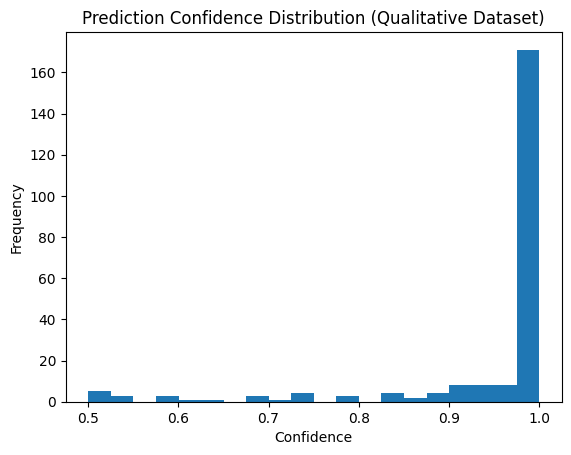

In [ ]:
import matplotlib.pyplot as plt

plt.hist(df_results["confidence"], bins=20)
plt.title("Prediction Confidence Distribution (Qualitative Dataset)")
plt.xlabel("Confidence")
plt.ylabel("Frequency")
plt.show()


In [ ]:
# Basic imports
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
model_files = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith(".keras") or file.endswith(".h5"):
            model_files.append(os.path.join(root, file))

print("Saved model files found:\n")
for f in model_files:
    print(f)


Saved model files found:

/content/drive/MyDrive/models/model_2_1.keras
/content/drive/MyDrive/Fruit_CNN_Models/phase1_baseline_cnn.keras
/content/drive/MyDrive/Fruit_CNN_Models/phase2_early_stopping.keras
/content/drive/MyDrive/Fruit_CNN_Models/phaseC1_cnn_augmented.keras
/content/drive/MyDrive/Fruit_CNN_Models/phaseC2_cnn_early_stop.keras
/content/drive/MyDrive/Fruit_CNN_Models/phaseD1_mobilenet_frozen.keras


In [ ]:
# ============================================================
# STEP 0: Imports and Global Configuration
# ============================================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# -----------------------------
# Reproducibility
# -----------------------------
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# -----------------------------
# Model & Image Parameters
# -----------------------------
IMG_SIZE = (224, 224)          # MobileNetV2 standard
BATCH_SIZE = 32
THRESHOLD = 0.5                # Fixed decision threshold

print("Environment ready.")


Environment ready.


In [ ]:
# ============================================================
# STEP 1: Load Trained MobileNetV2 Model
# ============================================================

MODEL_PATH = "/content/drive/MyDrive/Fruit_CNN_Models/phaseD1_mobilenet_frozen.keras"
# 🔁 CHANGE PATH if needed

model = load_model(MODEL_PATH)

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,750,277 (10.49 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 328,196 (1.25 MB)

In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/apple-gone-bad.jpg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Raw sigmoid output: 0.95311326


In [ ]:
import os

os.listdir("/content/drive/MyDrive")


['IMG-20240708-WA0001.jpg',
 'Classroom',
 'PRACT 4.docx',
 'Screenshot (8).png',
 'impact-of-internet-of-things-on-society-IJERTCONV5IS03020.pdf',
 'IMG-20241010-WA0035.jpg',
 'rakshit_ladda.pdf',
 'SAMEEKSHA-IOT (2).pptx',
 'SAMEEKSHA-IOT (1).pptx',
 'SAMEEKSHA-IOT.pptx',
 'Copy of ELECTRICALAPPROVAL.gdoc',
 'Screenshot 2024-11-08 113926.png',
 'eee assingment.pdf',
 'Document from Rakshit Ladda.pdf',
 'BT24ECE063. RAKSHIT LADDA.pdf',
 'SAMKEESHA IOT funal paper.pdf',
 'Screenshot_2025-01-19-21-04-30-312_com.phonepe.app.jpg',
 'Screenshot_2025-01-25-10-17-57-042_com.miui.gallery.jpg',
 'Screenshot_2025-04-19-16-14-39-959_com.phonepe.app.jpg',
 'Untitled spreadsheet.gsheet',
 'rakshit_check.png',
 'Colab Notebooks',
 'RAKSHIT_LADDA(BT24CSD066).png',
 'BT24CSD066(RAKSHIT LADDA).png',
 'RAKSHIT LADDA(BT24CSD066) LOGO.jpg',
 ' BRANCH_CHANGE_APPLICATION.gdoc',
 'BT24CSD066(RAKSHIT LADDA)MINDEASE.pdf',
 'Screenshot 2025-09-05 121312.png',
 'TF_2025_BROCHURE EVE1.pdf',
 '50_Startups (1).csv

In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/WhatsApp Image 2026-01-23 at 19.48.56.jpeg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
Raw sigmoid output: 0.7398415


In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/WhatsApp Image 2026-01-23 at 19.48.56 (1).jpeg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
Raw sigmoid output: 0.038485277


In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/WhatsApp Image 2026-01-23 at 19.48.55.jpeg"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Raw sigmoid output: 0.39176306


In [ ]:
import numpy as np
import tensorflow as tf

img_path = "/content/drive/MyDrive/rakshit_check.png"  # rotten image

img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))
img_arr = tf.keras.preprocessing.image.img_to_array(img)
img_arr = np.expand_dims(img_arr, axis=0)
img_arr = img_arr / 255.0

pred = model.predict(img_arr)
print("Raw sigmoid output:", pred[0][0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Raw sigmoid output: 0.99999964
